<a href="https://colab.research.google.com/github/letiscastros/InteligenciaArtifical_LinguagensFormais_Automatos/blob/main/DataShare_SE.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Aprendizado de Máquina – Sistema Especialista com Aprendizado Supervisionado
## DataShare-SE: Avaliação de Risco no Compartilhamento de Dados
**Disciplina:** Inteligência Artificial, Linguagens Formais e Autômatos | Sistemas Especialistas  
**Professora:** Profa. Kadidja Valéria  
**Alunos:** Letícia Castro de Souza e Lucas Eduardo Barreto de Oliveira


Execute as células de cima para baixo (`Ambiente de execução → Executar tudo`).

## 0. Estudo inicial (respostas)

**O que é aprendizado de máquina?**  
É a área da Inteligência Artificial em que o computador **aprende padrões a partir de dados** em vez de receber todas as regras escritas manualmente. Um modelo é ajustado com exemplos e depois usado para fazer previsões sobre casos novos.

**O que caracteriza o aprendizado supervisionado?**  
O modelo é treinado com exemplos que já trazem a **resposta correta (rótulo)**. Ele compara suas previsões com a resposta conhecida durante o treino para aprender a classificar casos futuros que nunca viu.

**O que são atributos e rótulos?**  
- **Atributos (`X`):** as características de entrada que descrevem o caso (`nivel_sensibilidade`, `nivel_permissao`, `qtd_destinatarios`, `pct_externos`).  
- **Rótulo (`y`):** a resposta conhecida que queremos prever (`risco`: `baixo`, `moderado` ou `alto`).

**Como classificação difere de regressão?**  
- **Classificação** prevê uma **categoria** discreta (como `baixo`, `moderado` ou `alto`), que é o caso deste trabalho.  
- **Regressão** prevê um **valor numérico contínuo** (como uma nota de risco de 0 a 100).

**Por que separar treino e teste?**  
Avaliar o modelo nos mesmos dados usados para treinar mediria apenas o quanto ele **decorou** os exemplos. Reservar uma parte para **teste** permite medir se o modelo realmente aprendeu a **generalizar** para casos inéditos.

## 1. Definição do problema

| Item | Definição |
|---|---|
| **Público** | Equipes de TI / Segurança da Informação e colaboradores que compartilham arquivos na organização |
| **Entradas do modelo (atributos)** | `nivel_sensibilidade` (1 pública, 2 interna, 3 confidencial, 4 restrita) · `nivel_permissao` (1 leitura, 2 edição, 3 edição + recompartilhar) · `qtd_destinatarios` · `pct_externos` (% de destinatários externos) |
| **Rótulo previsto (saída ML)** | `risco`: `baixo`, `moderado` ou `alto` |
| **Fato informado na consulta** | `autenticacao_forte` (`True`/`False`): indica se os destinatários utilizam autenticação em dois fatores (MFA) |
| **Recomendação final** | Ação de controle gerada pelas regras: *bloquear*, *exigir MFA*, *revisar permissões* ou *liberar* |

### Arquitetura Híbrida (Aprendizado de Máquina + Regras)
- **Modelo de Aprendizado de Máquina (Árvore de Decisão):** diagnostica o **risco inerente** da operação com base nos atributos históricos do compartilhamento.
- **Sistema Especialista (Base de 5 Regras):** combina o risco previsto pelo modelo com o contexto informado na hora (`autenticacao_forte` e política de dados restritos) para recomendar a ação de segurança.

## 2. Preparar o ambiente
Importamos apenas as bibliotecas essenciais (`pandas`, `matplotlib` e `scikit-learn`). No Google Colab todas já vêm instaladas por padrão.

In [1]:
import pandas as pd
from io import StringIO
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

## 3. Dataset rotulado

**Ficha do dataset**
- **Quantidade de registros:** 150 casos simulados (47 `baixo`, 56 `moderado`, 47 `alto`).
- **Origem:** dataset sintético construído especificamente para este estudo de caso, simulando solicitações de compartilhamento de arquivos corporativos.
- **Critério de rotulação:** combina a sensibilidade da informação, o nível de permissão concedido, o alcance de destinatários e a exposição externa.

In [2]:
# Dataset simulado embutido
CSV = """nivel_sensibilidade,nivel_permissao,qtd_destinatarios,pct_externos,risco
1,2,55,70,moderado
3,1,33,10,moderado
1,2,26,10,baixo
1,2,50,70,moderado
4,2,42,25,moderado
4,2,57,50,alto
1,1,23,65,baixo
2,2,60,25,moderado
4,2,18,90,alto
1,3,35,10,baixo
3,3,42,75,alto
3,2,18,85,alto
3,3,9,70,moderado
1,2,39,15,baixo
1,1,57,35,baixo
2,1,25,100,moderado
3,3,36,80,alto
1,3,42,5,baixo
1,3,4,35,baixo
4,2,47,30,alto
1,2,41,15,baixo
1,1,19,60,baixo
3,1,12,20,baixo
2,2,35,30,moderado
4,2,9,50,moderado
4,2,47,75,alto
4,2,52,70,alto
3,3,25,95,alto
2,2,13,15,baixo
2,1,35,80,moderado
4,3,59,10,alto
2,1,1,100,moderado
4,3,39,20,alto
1,2,32,5,baixo
1,3,28,50,moderado
1,3,5,60,moderado
3,2,41,60,alto
2,3,31,35,moderado
4,3,41,35,alto
2,3,50,5,moderado
4,2,23,65,alto
3,3,46,50,alto
2,3,38,70,alto
2,2,15,15,baixo
2,2,43,0,baixo
2,3,42,90,alto
3,2,54,0,moderado
2,1,19,100,moderado
1,3,31,25,baixo
1,1,38,30,baixo
4,1,11,85,moderado
2,3,32,15,moderado
1,2,17,55,baixo
1,1,40,45,baixo
4,3,40,25,moderado
4,3,45,0,moderado
1,3,8,5,baixo
3,3,60,20,moderado
3,3,32,95,alto
2,2,52,85,moderado
4,3,59,65,alto
4,2,56,60,alto
1,1,15,70,baixo
2,1,47,45,moderado
4,3,9,20,moderado
2,2,50,50,moderado
2,2,26,90,moderado
1,1,45,0,baixo
4,1,46,60,alto
4,3,51,55,alto
2,2,3,35,moderado
4,2,18,5,moderado
2,1,47,15,baixo
4,1,15,30,moderado
4,2,46,65,alto
2,3,57,80,alto
2,1,33,30,baixo
3,1,31,90,alto
1,2,22,20,baixo
4,3,18,65,alto
1,1,32,40,baixo
3,1,42,0,moderado
1,3,12,30,baixo
4,3,14,70,alto
1,3,33,0,baixo
1,2,8,10,baixo
4,2,16,65,alto
1,1,59,0,baixo
2,1,2,85,moderado
1,1,59,20,baixo
3,1,36,80,moderado
4,1,53,35,moderado
1,1,3,40,baixo
4,3,45,10,moderado
3,2,48,80,alto
3,3,60,20,moderado
2,1,8,80,moderado
1,1,59,90,moderado
1,2,12,15,baixo
1,3,22,25,moderado
1,2,45,0,baixo
3,2,43,0,moderado
3,2,33,90,alto
2,3,18,55,moderado
3,1,15,20,baixo
4,1,21,80,alto
4,2,21,50,alto
4,1,38,90,alto
3,2,21,90,alto
1,2,6,10,baixo
4,3,5,20,moderado
4,1,49,45,alto
1,1,55,40,baixo
4,3,37,40,alto
3,3,9,15,moderado
1,1,56,30,baixo
1,1,48,65,moderado
3,3,48,95,alto
2,1,34,65,moderado
1,3,12,45,moderado
3,1,11,20,baixo
2,1,57,75,moderado
4,3,35,95,alto
2,2,56,75,moderado
1,1,36,10,baixo
4,1,9,60,moderado
4,3,53,0,moderado
4,2,17,75,alto
4,1,21,80,alto
1,1,30,65,baixo
4,2,17,100,alto
1,3,39,80,moderado
4,3,4,95,alto
2,1,54,0,baixo
3,3,59,70,alto
4,2,30,75,alto
4,3,52,100,alto
1,1,39,10,baixo
2,1,25,95,moderado
1,1,55,55,moderado
3,2,42,55,moderado
4,1,30,0,moderado
3,3,43,55,alto
4,1,2,0,baixo
3,1,29,0,baixo
3,2,32,75,alto
2,2,44,45,moderado
1,1,48,50,baixo
2,2,1,20,baixo
1,3,26,0,baixo
"""
dados = pd.read_csv(StringIO(CSV))

# Para usar o arquivo CSV no lugar do texto embutido (após fazer upload no Colab):
# dados = pd.read_csv("dataset_risco_compartilhamento.csv")

print(dados.head(15).to_string(index=False))
print("\nTotal de registros:", len(dados))
print("\nQuantidade por classe:")
print(dados["risco"].value_counts())
print("\nResumo dos atributos:")
print(dados.describe().loc[["min", "max"]].to_string())

 nivel_sensibilidade  nivel_permissao  qtd_destinatarios  pct_externos    risco
                   1                2                 55            70 moderado
                   3                1                 33            10 moderado
                   1                2                 26            10    baixo
                   1                2                 50            70 moderado
                   4                2                 42            25 moderado
                   4                2                 57            50     alto
                   1                1                 23            65    baixo
                   2                2                 60            25 moderado
                   4                2                 18            90     alto
                   1                3                 35            10    baixo
                   3                3                 42            75     alto
                   3                2   

## 4. Separar treinamento e teste
Separamos os atributos (`X`) do rótulo (`y`) e dividimos os dados em **75% para treino** (112 registros) e **25% para teste** (38 registros), usando `stratify=y` para manter a proporção das três classes de risco.

In [3]:
COLUNAS = ["nivel_sensibilidade", "nivel_permissao", "qtd_destinatarios", "pct_externos"]

X = dados[COLUNAS]
y = dados["risco"]

X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

print(f"Total: {len(dados)} | Treino: {len(X_treino)} | Teste: {len(X_teste)}")
print("Distribuição das classes no treino:")
print(y_treino.value_counts().to_string())

Total: 150 | Treino: 112 | Teste: 38
Distribuição das classes no treino:
risco
moderado    42
baixo       35
alto        35


## 5. Treinar e avaliar o modelo
Utilizamos uma **Árvore de Decisão (`DecisionTreeClassifier`)** com profundidade máxima igual a 3 (`max_depth=3`) e mínimo de 3 amostras por folha (`min_samples_leaf=3`). Essa configuração evita superajuste (*overfitting*) e mantém a árvore visualmente clara e fácil de auditar.

Acurácia no conjunto de teste: 76.3%
Matriz de confusão (linhas = real, colunas = previsto):
          baixo  moderado  alto
baixo         9         3     0
moderado      3        10     1
alto          0         2    10


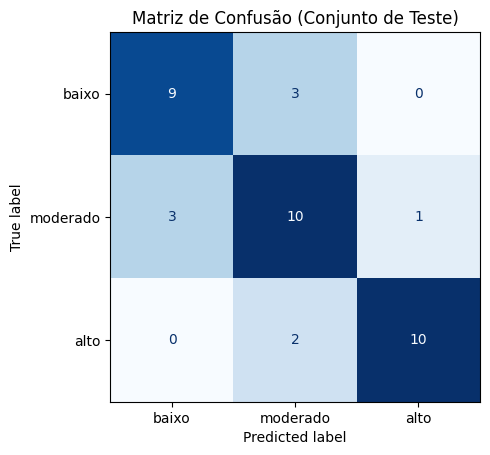

In [4]:
# Treinamento do modelo apenas com os dados de treino
modelo = DecisionTreeClassifier(max_depth=3, min_samples_leaf=3, random_state=42)
modelo.fit(X_treino, y_treino)

# Avaliação no conjunto de teste
previsoes = modelo.predict(X_teste)
acuracia = accuracy_score(y_teste, previsoes)
print(f"Acurácia no conjunto de teste: {acuracia:.1%}")

# Matriz de confusão
classes = ["baixo", "moderado", "alto"]
matriz = confusion_matrix(y_teste, previsoes, labels=classes)
print("Matriz de confusão (linhas = real, colunas = previsto):")
print(pd.DataFrame(matriz, index=classes, columns=classes))

ConfusionMatrixDisplay(matriz, display_labels=classes).plot(cmap="Blues", colorbar=False)
plt.title("Matriz de Confusão (Conjunto de Teste)")
plt.show()

### Interpretabilidade: importância dos atributos e estrutura da árvore
Uma das principais vantagens da Árvore de Decisão em Segurança da Informação é a **explicabilidade**: conseguimos inspecionar exatamente quais critérios o modelo aprendeu.

Importância de cada atributo na decisão:
nivel_sensibilidade    0.545
pct_externos           0.330
nivel_permissao        0.125
qtd_destinatarios      0.000
Regras aprendidas pela árvore:
|--- nivel_sensibilidade <= 1.50
|   |--- pct_externos <= 42.50
|   |   |--- class: baixo
|   |--- pct_externos >  42.50
|   |   |--- nivel_permissao <= 1.50
|   |   |   |--- class: baixo
|   |   |--- nivel_permissao >  1.50
|   |   |   |--- class: moderado
|--- nivel_sensibilidade >  1.50
|   |--- pct_externos <= 37.50
|   |   |--- nivel_permissao <= 1.50
|   |   |   |--- class: baixo
|   |   |--- nivel_permissao >  1.50
|   |   |   |--- class: moderado
|   |--- pct_externos >  37.50
|   |   |--- nivel_sensibilidade <= 2.50
|   |   |   |--- class: moderado
|   |   |--- nivel_sensibilidade >  2.50
|   |   |   |--- class: alto



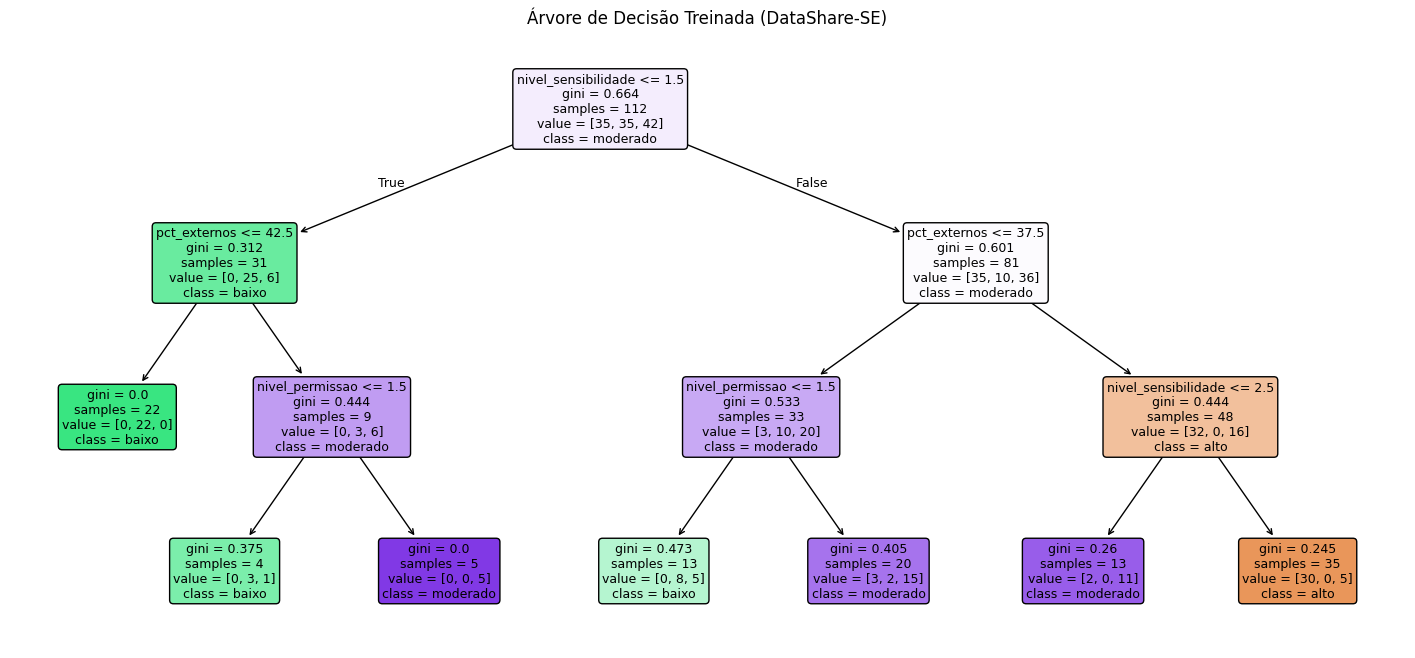

In [5]:
importancias = pd.Series(modelo.feature_importances_, index=COLUNAS).sort_values(ascending=False)
print("Importância de cada atributo na decisão:")
print(importancias.round(3).to_string())

print("Regras aprendidas pela árvore:")
print(export_text(modelo, feature_names=COLUNAS))

plt.figure(figsize=(18, 8))
plot_tree(
    modelo,
    feature_names=COLUNAS,
    class_names=list(modelo.classes_),
    filled=True,
    rounded=True,
    fontsize=9
)
plt.title("Árvore de Decisão Treinada (DataShare-SE)")
plt.show()

## 6. Base de conhecimento e motor de inferência
A previsão gerada pelo modelo de Machine Learning (`risco`) passa a ser um **fato** dentro do Sistema Especialista. Junto com os dados da consulta e com o fato informado pelo usuário (`autenticacao_forte`), o motor de inferência avalia **5 regras explícitas** definidas pelo especialista:

| Regra | Condição | Recomendação | Justificativa (Origem) |
|---|---|---|---|
| **R1** | `nivel_sensibilidade == 4` e `pct_externos > 0` | **Bloquear compartilhamento** | Política de conformidade (LGPD / ISO 27001): dados restritos não saem da organização sem aprovação formal. |
| **R2** | `risco == 'alto'` e `autenticacao_forte == False` | **Bloquear e exigir MFA** | Alto risco de exposição combinado com ausência de MFA eleva criticamente a chance de vazamento. |
| **R3** | `risco == 'alto'` e `autenticacao_forte == True` | **Revisar permissões e aprovar com prazo** | O MFA mitiga acesso indevido, mas o risco alto exige revisão de privilégio mínimo e expiração. |
| **R4** | `risco == 'moderado'` e `autenticacao_forte == False` | **Solicitar autenticação forte (MFA)** | Risco moderado exige uma camada extra de verificação antes da liberação. |
| **R5** | `risco == 'baixo'` ou (`risco == 'moderado'` e `autenticacao_forte == True`) | **Liberar compartilhamento** | Operação dentro dos limites aceitáveis de risco e controles de acesso. |

In [6]:
# BASE DE CONHECIMENTO (5 Regras do Especialista)

regras = [
    {
        "id": "R1",
        "condicao": lambda f: f["nivel_sensibilidade"] == 4 and f["pct_externos"] > 0,
        "acao": "Bloquear compartilhamento.",
        "justificativa": "Política de segurança (LGPD / ISO 27001): dados restritos não podem sair da organização sem aprovação formal.",
    },
    {
        "id": "R2",
        "condicao": lambda f: f["risco"] == "alto" and not f["autenticacao_forte"],
        "acao": "Bloquear e exigir autenticação forte (MFA).",
        "justificativa": "Alto risco de exposição sem autenticação forte eleva criticamente a chance de vazamento.",
    },
    {
        "id": "R3",
        "condicao": lambda f: f["risco"] == "alto" and f["autenticacao_forte"],
        "acao": "Revisar permissões (privilégio mínimo) e aprovar com prazo de expiração.",
        "justificativa": "O MFA mitiga acesso indevido, mas o risco inerente alto exige revisão de permissões.",
    },
    {
        "id": "R4",
        "condicao": lambda f: f["risco"] == "moderado" and not f["autenticacao_forte"],
        "acao": "Solicitar autenticação forte (MFA) antes de liberar.",
        "justificativa": "Risco moderado exige uma camada adicional de verificação de identidade.",
    },
    {
        "id": "R5",
        "condicao": lambda f: f["risco"] == "baixo" or (f["risco"] == "moderado" and f["autenticacao_forte"]),
        "acao": "Liberar compartilhamento.",
        "justificativa": "Operação dentro dos parâmetros aceitáveis de risco e controles de acesso.",
    },
]

# MOTOR DE INFERÊNCIA

def inferir(fatos):
    for regra in regras:
        if regra["condicao"](fatos):
            return {
                "regra_aplicada": regra["id"],
                "recomendacao": regra["acao"],
                "justificativa": regra["justificativa"],
            }
    raise ValueError("Nenhuma regra compatível com os fatos informados.")

## 7. Integrar o modelo ao sistema especialista e testar casos novos
A função `orientar_compartilhamento` recebe os atributos do compartilhamento e o fato `autenticacao_forte`:
1. Valida os valores de entrada;
2. Usa a **Árvore de Decisão** para prever o nível de risco;
3. Envia os fatos ao **motor de inferência** para obter a recomendação e a justificativa.

In [7]:
def orientar_compartilhamento(sensibilidade, permissao, qtd_dest, pct_ext, autenticacao_forte):
    # Validação básica das entradas
    if sensibilidade not in (1, 2, 3, 4):
        raise ValueError("Sensibilidade deve ser 1, 2, 3 ou 4.")
    if permissao not in (1, 2, 3):
        raise ValueError("Permissão deve ser 1, 2 ou 3.")
    if qtd_dest < 1 or not (0 <= pct_ext <= 100):
        raise ValueError("Verifique quantidade de destinatários (>= 1) e percentual externo (0 a 100).")
    if not isinstance(autenticacao_forte, bool):
        raise ValueError("autenticacao_forte deve ser True ou False.")

    # 1. Previsão do modelo de Machine Learning
    novo_caso = pd.DataFrame([{
        "nivel_sensibilidade": sensibilidade,
        "nivel_permissao": permissao,
        "qtd_destinatarios": qtd_dest,
        "pct_externos": pct_ext,
    }])
    risco_previsto = modelo.predict(novo_caso)[0]

    # 2. Execução do Sistema Especialista (Regras)
    fatos = {
        "nivel_sensibilidade": sensibilidade,
        "nivel_permissao": permissao,
        "qtd_destinatarios": qtd_dest,
        "pct_externos": pct_ext,
        "autenticacao_forte": autenticacao_forte,
        "risco": risco_previsto,
    }
    decisao = inferir(fatos)

    return {
        "risco_previsto": risco_previsto,
        "regra_aplicada": decisao["regra_aplicada"],
        "recomendacao": decisao["recomendacao"],
        "justificativa": decisao["justificativa"],
    }

# Testando 3 casos novos (que não estavam no dataset)
casos_teste = [
    ("Caso 1 (Dado restrito para externos)", (4, 2, 8, 40, False)),
    ("Caso 2 (Dado confidencial sem MFA)",    (3, 2, 20, 25, False)),
    ("Caso 3 (Dado público interno com MFA)", (1, 1, 4, 0, True)),
]

for titulo, params in casos_teste:
    res = orientar_compartilhamento(*params)
    print(f"=== {titulo} ===")
    print(f"Entradas: sensibilidade={params[0]}, permissao={params[1]}, dest={params[2]}, ext={params[3]}%, MFA={params[4]}")
    print(f"Risco previsto (ML): {res['risco_previsto']}")
    print(f"Regra disparada    : {res['regra_aplicada']}")
    print(f"Recomendação       : {res['recomendacao']}")
    print(f"Justificativa      : {res['justificativa']}")

# Demonstração extra: mudando apenas o fato autenticacao_forte no Caso 2
print("=== Teste de variação de fato (Caso 2 com MFA = True) ===")
res_mfa = orientar_compartilhamento(3, 2, 20, 25, True)
print(f"Risco previsto (ML): {res_mfa['risco_previsto']} -> Regra {res_mfa['regra_aplicada']}: {res_mfa['recomendacao']}")

=== Caso 1 (Dado restrito para externos) ===
Entradas: sensibilidade=4, permissao=2, dest=8, ext=40%, MFA=False
Risco previsto (ML): alto
Regra disparada    : R1
Recomendação       : Bloquear compartilhamento.
Justificativa      : Política de segurança (LGPD / ISO 27001): dados restritos não podem sair da organização sem aprovação formal.
=== Caso 2 (Dado confidencial sem MFA) ===
Entradas: sensibilidade=3, permissao=2, dest=20, ext=25%, MFA=False
Risco previsto (ML): moderado
Regra disparada    : R4
Recomendação       : Solicitar autenticação forte (MFA) antes de liberar.
Justificativa      : Risco moderado exige uma camada adicional de verificação de identidade.
=== Caso 3 (Dado público interno com MFA) ===
Entradas: sensibilidade=1, permissao=1, dest=4, ext=0%, MFA=True
Risco previsto (ML): baixo
Regra disparada    : R5
Recomendação       : Liberar compartilhamento.
Justificativa      : Operação dentro dos parâmetros aceitáveis de risco e controles de acesso.
=== Teste de variação d

## 8. Análise dos resultados e perguntas da disciplina

### Interpretação dos 3 casos testados
- **Caso 1 (sensibilidade 4, edição, 8 destinatários, 40% externos, sem MFA):** o modelo previu risco `alto` e a regra **R1** bloqueou o envio imediatamente por envolver dado restrito para público externo. Mesmo que o modelo tivesse classificado o risco como menor, a R1 funcionaria como trava de política de segurança.
- **Caso 2 (sensibilidade 3, edição, 20 destinatários, 25% externos, sem MFA):** o modelo previu risco `moderado`. Como não há autenticação forte, a regra **R4** exigiu MFA antes da liberação. Ao ativar `autenticacao_forte=True`, o risco previsto continua `moderado`, mas a regra muda para **R5**, liberando o compartilhamento.
- **Caso 3 (sensibilidade 1, leitura, 4 destinatários, 0% externos, com MFA):** o modelo previu risco `baixo` e a regra **R5** liberou o acesso sem burocracia desnecessária.

### Perguntas para análise
1. **Qual parte do programa aprende com os dados?**  
   Apenas o `DecisionTreeClassifier` (`modelo`). Ele identifica nos dados de treino quais combinações de sensibilidade, permissão, destinatários e externos levam a risco `baixo`, `moderado` ou `alto`.
2. **Qual parte aplica regras humanas?**  
   A lista `regras` (base de conhecimento) e a função `inferir` (motor de inferência), escritas explicitamente com base em boas práticas de segurança da informação.
3. **Por que `autenticacao_forte` não entrou nos atributos do modelo?**  
   Porque ela é um **controle de segurança** aplicado no momento da solicitação, e não uma característica intrínseca do arquivo ou do público. Mantê-la nas regras permite alterar a decisão sem precisar retreinar o modelo.
4. **Uma acurácia de ~76% no teste é suficiente para uso real?**  
   Não para automação total sem supervisão. O dataset possui apenas 150 registros simulados (38 no teste) e não contempla variáveis reais como histórico do usuário ou tipo exato do documento. Por isso, em produção o sistema deve atuar como apoio à decisão humana, aliado a regras rígidas de bloqueio como a **R1**.

## 9. Ética e Impactos da Inteligência Artificial

### 9.1. Apresentação ética do projeto
O **DataShare-SE** é um sistema especialista híbrido de apoio à decisão voltado à Segurança da Informação corporativa, criado para avaliar o risco do compartilhamento de arquivos antes do envio a destinatários internos ou externos. Os usuários diretos são colaboradores que compartilham documentos e equipes de TI/Segurança, enquanto os afetados pelas decisões são os próprios colaboradores (que têm solicitações liberadas ou bloqueadas) e os titulares dos dados presentes nos arquivos. A Inteligência Artificial participa por meio de uma **Árvore de Decisão (`DecisionTreeClassifier`)**, que analisa quatro atributos (`nivel_sensibilidade`, `nivel_permissao`, `qtd_destinatarios` e `pct_externos`) para prever o risco inerente (`baixo`, `moderado` ou `alto`). Essa previsão alimenta o **Sistema Especialista**, onde cinco regras explícitas definidas pela equipe (`R1` a `R5`) cruzam o risco previsto com o fato `autenticacao_forte` (MFA) para emitir a recomendação final: *bloquear* (`R1` e `R2`), *revisar permissões* (`R3`), *solicitar MFA* (`R4`) ou *liberar* (`R5`).

### 9.2. Análise dos aspectos éticos

| Aspecto | Situação concreta no DataShare-SE | Quem pode ser afetado | Medida adotada pela equipe |
|---|---|---|---|
| **Privacidade e dados** | O sistema usa apenas metadados operacionais (`nivel_sensibilidade`, `nivel_permissao`, `qtd_destinatarios`, `pct_externos` e status booleano de MFA), sem ler o conteúdo dos arquivos nem coletar nomes ou e-mails. O treino utilizou 150 registros sintéticos. | Titulares dos dados nos arquivos compartilhados e colaboradores solicitantes, caso logs de bloqueio exponham tentativas de envio. | Aplicar minimização de dados (coletar apenas metadados necessários, sem inspecionar o documento) e anonimizar identificadores nos registros de auditoria. |
| **Viés e equidade** | Como os 150 dados são simulados e `pct_externos` tem peso de 33% na árvore, o modelo pode penalizar setores que trabalham legitimamente com parceiros externos (ex.: jurídico ou compras), classificando envios rotineiros como `alto` risco. | Equipes com alta demanda de comunicação externa, sofrendo bloqueios recorrentes e atrasos injustificados. | Auditar a matriz de confusão por departamento, recalibrar o modelo com dados reais validados por especialistas e criar listas de exceção para parceiros homologados. |
| **Transparência** | Exibir apenas *"Compartilhamento bloqueado"* impediria o usuário de saber se a decisão veio de uma previsão estatística da árvore ou de uma regra fixa de conformidade. | Colaboradores solicitantes e gestores que precisam entender o bloqueio para ajustar permissões ou pedir liberação. | Exibir na saída o risco previsto pelo ML, o código da regra disparada (`R1` a `R5`) e a justificativa textual clara, além de manter a árvore rasa (`max_depth=3`) para auditoria visual. |
| **Supervisão e responsabilidade** | Com acurácia de **76,3%** no teste, cerca de 23,7% das previsões podem classificar incorretamente o risco (subestimando um vazamento ou bloqueando um envio legítimo). | A organização (em caso de falso negativo que gere vazamento) e o colaborador (em caso de falso positivo que trave uma entrega urgente). | Operar o sistema exclusivamente como **apoio à decisão**, atribuir a revisão de exceções à **Equipe de Segurança da Informação / TI** e oferecer canal rápido de contestação. |
| **Impacto social** | Protege dados sensíveis de clientes e cidadãos contra vazamentos, mas, se tratado como infalível, pode burocratizar o trabalho ou gerar falsa sensação de segurança. | Titulares de dados pessoais (protegidos contra exposição) e colaboradores (impactados na agilidade operacional). | Manter travas determinísticas independentes do ML (como a regra `R1` para dados restritos externos) e orientar os usuários sobre classificação de dados. |

### 9.3. Dilema ético, fundamentação e reflexão individual

* **Dilema ético:** Quando o modelo prevê risco `moderado` ou `alto` (por exemplo, envio de arquivo confidencial para externos sem MFA), o sistema deve **bloquear preventivamente a operação** até revisão humana ou **apenas emitir um alerta**, deixando o usuário assumir o risco e concluir o envio?
  * *Alternativa 1 (Bloqueio preventivo):* Maximiza a proteção e a conformidade com a LGPD, mas falsos positivos (~23,7% de erro do modelo) podem atrasar demandas urgentes e sobrecarregar a TI.
  * *Alternativa 2 (Alerta sem bloqueio):* Mantém a agilidade operacional, mas expõe dados sensíveis a vazamentos irreversíveis por erro humano, transferindo um risco institucional ao colaborador.
* **Fundamentação (Artigo e Vídeo da aula):**
  * *Artigo (*Lacerda Júnior, 2026 — "Da proibição à governança"*):* No plano da **integridade acadêmica**, o artigo alerta que declarar o uso de IA generativa exige transparência sobre o que foi gerado pela ferramenta e comprovação de validação autoral, evitando a delegação acrítica do raciocínio técnico. No plano do projeto, reforça a transição de bloqueios puramente proibitivos para uma governança rastreável e com supervisão humana.
  * *Vídeo (*IEA-USP, 2026 — "O Estado da Arte em Ética na Inteligência Artificial", trecho `[01:36:13]` a `[01:41:25]`):** O pesquisador Steven Gouveia analisa os riscos éticos de sistemas de apoio à decisão, alertando que essas ferramentas não são neutras nos dados e que, sem transparência e literacia técnica, levam o usuário a aceitar a recomendação da máquina de forma cega. Ele defende que a IA atue apenas como instrumento auxiliar dentro de uma decisão partilhada com supervisão humana, princípio aplicado diretamente no DataShare-SE ao manter a Árvore de Decisão como apoio e exigir revisão da equipe de TI/Segurança em casos críticos.
* **Reflexão individual:** Manteria a abordagem intermediária já implementada nas regras `R1` e `R4`: bloqueio rígido apenas em violações objetivas de política (`R1` — dado restrito para externos), enquanto nos casos de risco `moderado` (`R4`) o sistema não bloqueia em definitivo, mas exige a ativação de um controle técnico (MFA) para liberar o envio. O argumento decisivo é equilibrar segurança e proporcionalidade, evitando que erros estatísticos paralisem o trabalho legítimo. Para verificar se a medida funciona, acompanharia mensalmente a **taxa de falsos positivos** (bloqueios revertidos pela TI) e a **redução de envios externos sem MFA**.

### 9.4. Declaração de uso de sistemas de IA

* **IA incorporada ao projeto:**  
  O projeto utiliza um **modelo supervisionado de Árvore de Decisão (`DecisionTreeClassifier`, biblioteca `scikit-learn`) integrado a um Sistema Especialista baseado em 5 regras** para classificar o risco de compartilhamento de arquivos e recomendar ações de controle de acesso. O sistema recebe quatro atributos numéricos (`nivel_sensibilidade`, `nivel_permissao`, `qtd_destinatarios` e `pct_externos`) além do fato booleano `autenticacao_forte`, e gera como saída o risco previsto (`baixo`, `moderado` ou `alto`), a regra disparada (`R1` a `R5`), a recomendação e sua justificativa. A equipe verificou seu funcionamento por meio de divisão estratificada entre treino (75%) e teste (25%), análise da matriz de confusão (acurácia de 76,3%), visualização da árvore gerada e testes com casos novos e variação de fatos. As limitações identificadas incluem o uso de dataset sintético pequeno (150 registros), ausência de variáveis contextuais reais (como histórico do usuário ou conteúdo do arquivo) e margem de erro de ~23,7%, exigindo revisão humana em casos contestados ou críticos. A revisão cabe à **equipe de Segurança da Informação / TI responsável pela governança de dados**.

* **IA utilizada na elaboração do trabalho:**  
  Utilizei **Gemini (Google)** para auxiliar na organização didática do notebook, na simplificação da base de regras e na estruturação textual desta análise ética. Aproveitei a estruturação das células Python, a organização das tabelas e o apoio na redação técnica após executar integralmente o código no Google Colab, conferir os resultados da matriz de confusão e da acurácia, testar manualmente todas as regras (`R1` a `R5`) e adequar os argumentos ao contexto do projeto DataShare-SE. Assumo a responsabilidade pelas escolhas, verificações e conteúdo da entrega.

## Referências
- IBM. *Guia de Aprendizado de Máquina*: https://www.ibm.com/br-pt/think/machine-learning
- Scikit-learn. *DecisionTreeClassifier & train_test_split*: https://scikit-learn.org
- Material didático da disciplina de Inteligência Artificial e LFA — Profa. Kadidja Valéria.